<a href="https://colab.research.google.com/github/NathanDev2/cnn_and_resnet_evaluation/blob/nathan-edits-cnn_and_resnet_evaluation/facial_recognition_dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Facial Expression Recognition with Limited Data
This notebook compares two deep learning models, a convolutional neural network (CNN) built from scratch and a ResNet, at recognizing facial expressions across 8 emotions, using the FER+ dataset.

**Research question:** When training data is limited, how much does data augmentation improve each model's accuracy, and does it help one architecture more than the other?

To answer it, we train each model on 10%, 25%, 50% and 100% of the training data, with augmentation turned off and on, and compare their accuracy on the same held-out test set.

## Authors
* Drew
* Nathan Darrett
* Author Name 3

Course: **Deep Learning, Fall 2026**

# 1. Setup

Prepares the Colab machine: installs the extra library we need, loads all libraries, makes results repeatable, selects the GPU, and connects Google Drive for permanent storage.

## 1a. Install packages

Colab already includes PyTorch, NumPy, pandas and matplotlib. We only need to add `kagglehub`, which downloads the face images directly from Kaggle.

In [ ]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


## 1b. Import libraries

All libraries used in the project, loaded in one place:

- `torch`, `torch.nn`: PyTorch, used to build and train the models
- `torchvision`: loads image folders and applies data augmentation
- `numpy`, `pandas`: numbers and result tables
- `matplotlib`: charts and learning curves
- `PIL`: opening images
- `kagglehub`: downloading the dataset

In [ ]:
import os, glob, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import kagglehub

c:\Users\willd\OneDrive\Desktop\dl_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1c. Set the random seed

Many steps in deep learning are random: the starting weights, which images go into each data subset, the order images are shown, and which images get augmented. Fixing the seed makes every run repeatable, so a change in accuracy reflects a real difference rather than luck. Python, NumPy and PyTorch each have their own random generator, so all three are seeded.

In [ ]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## 1d. Select the GPU

Training on a GPU is many times faster than on a CPU. This cell uses the GPU when one is available and prints which one. In Colab, enable it under Runtime > Change runtime type > T4 GPU.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

Using: cuda NVIDIA GeForce RTX 5070 Ti


## 1e. Choose where to save results

Colab deletes all files when a session ends, so in Colab we mount Google Drive and save trained results there, where they don't need to be recreated each session. When the notebook runs on your own computer (for example in VS Code), Google Drive isn't available, so results are saved to a local `project_data` folder next to the notebook instead. The cell detects which one it is running in.

In [ ]:
try:
    from google.colab import drive   # only exists in Colab
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/facial-expression-dl'
except ImportError:
    PROJECT_DIR = 'project_data'     # running on your own computer: a local folder
os.makedirs(PROJECT_DIR, exist_ok=True)
print('Saving results to:', os.path.abspath(PROJECT_DIR))

Saving results to: c:\Users\willd\OneDrive\Desktop\dl_project\project_data


# 2. Get the Data

We use **FER+**, a facial expression dataset from Microsoft: about 35,900 grayscale face images (48x48 pixels), already cropped and centered, labeled with 8 emotions (neutral, happiness, surprise, sadness, anger, disgust, fear, contempt). The images are the ones from the FER-2013 challenge; FER+ gives every image a new, more reliable label.

The data comes in two files that list the images in the same order:
- `fer2013.csv` (the original FER-2013 challenge file, from Kaggle): the pixels of each image, stored as text
- `fer2013new.csv` (from [Microsoft's FER+ GitHub](https://github.com/microsoft/FERPlus)): the labels for each image

FER+ comes with three official splits, which we keep as published: **Training** for training, **PublicTest** as our validation set, and **PrivateTest** as our final test set.

## 2a. Download the data

`kagglehub` downloads the pixel file from Kaggle, and pandas reads the label file straight from GitHub. We check that both files have the same number of rows in the same order, so row *i* of one file matches row *i* of the other.

In [ ]:
PIXELS_DIR = kagglehub.dataset_download('deadskull7/fer2013')
pixels = pd.read_csv(os.path.join(PIXELS_DIR, 'fer2013.csv'))

FERPLUS_URL = 'https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv'
label_table = pd.read_csv(FERPLUS_URL)

print('Pixel rows:', len(pixels), '| Label rows:', len(label_table))
print('Same order:', (pixels['Usage'] == label_table['Usage']).all())
display(label_table.head())

100%|██████████| 96.6M/96.6M [00:02<00:00, 36.6MB/s]

Extracting files...


Pixel rows: 35887 | Label rows: 35887
Same order: True


,Usage,Image name,neutral,happiness,surprise,sadness,anger,disgust,fear,contempt,unknown,NF
0,Training,fer0000000.png,4,0,0,1,3,2,0,0,0,0
1,Training,fer0000001.png,6,0,1,1,0,0,0,0,2,0
2,Training,fer0000002.png,5,0,0,3,1,0,0,0,1,0
3,Training,fer0000003.png,4,0,0,4,1,0,0,0,1,0
4,Training,fer0000004.png,9,0,0,1,0,0,0,0,0,0


## 2b. Get one label per image

The label file gives each image a score for every emotion, so we take the highest-scoring emotion as the image's label. Images marked "unknown" or "not a face" (NF), or with no clear top emotion, are dropped.

Then we turn each image's pixel text into a 48x48 grayscale image and group the images by split. Each split becomes a list of `(image, emotion)` pairs.

In [ ]:
EMOTIONS = ['neutral', 'happiness', 'surprise', 'sadness', 'anger', 'disgust', 'fear', 'contempt']
emotions = EMOTIONS
choices = label_table[EMOTIONS + ['unknown', 'NF']]

top_score = choices.max(axis=1)
n_tied = choices.eq(top_score, axis=0).sum(axis=1)   # how many choices share the top score
winner = choices.idxmax(axis=1)                       # the top-scoring choice
keep = (n_tied == 1) & winner.isin(EMOTIONS)          # one clear winner, and it is an emotion
print('Images kept:', keep.sum(), '| dropped:', (~keep).sum())

SPLITS = {'train': 'Training', 'val': 'PublicTest', 'test': 'PrivateTest'}
data = {}   # split -> list of (image, emotion)
for split, usage in SPLITS.items():
    rows = keep & (label_table['Usage'] == usage)
    data[split] = [(Image.fromarray(np.array(p.split(), dtype=np.uint8).reshape(48, 48)), emotion)
                   for p, emotion in zip(pixels.loc[rows, 'pixels'], winner[rows])]
    print(f'{split}: {len(data[split])} images')

Images kept: 33712 | dropped: 2175
train: 26940 images
val: 3396 images
test: 3376 images


## 2c. Images per emotion

The report needs the size of each split and how balanced the emotions are. The emotions are very imbalanced (few "disgust", "fear" and "contempt" images), so we will report accuracy per emotion as well as overall.

,train,val,test
neutral,9365,1242,1166
happiness,7410,880,909
surprise,3378,441,421
sadness,3403,395,424
anger,2399,310,316
disgust,175,31,22
fear,648,73,92
contempt,162,24,26
TOTAL,26940,3396,3376


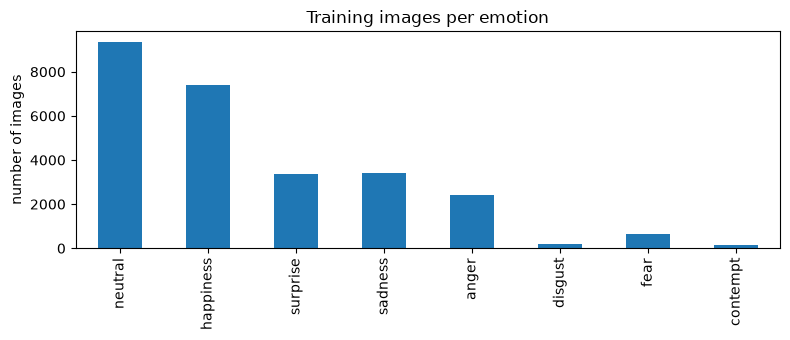

In [ ]:
table = pd.DataFrame({split: pd.Series([e for _, e in items]).value_counts()
                      for split, items in data.items()}).reindex(EMOTIONS).fillna(0).astype(int)
table.loc['TOTAL'] = table.sum()
display(table)

table.drop('TOTAL')['train'].plot.bar(figsize=(8, 3.5), title='Training images per emotion')
plt.ylabel('number of images')
plt.tight_layout()
plt.show()

## 2d. Example faces

Six training examples per emotion, as a visual check of the images and labels.

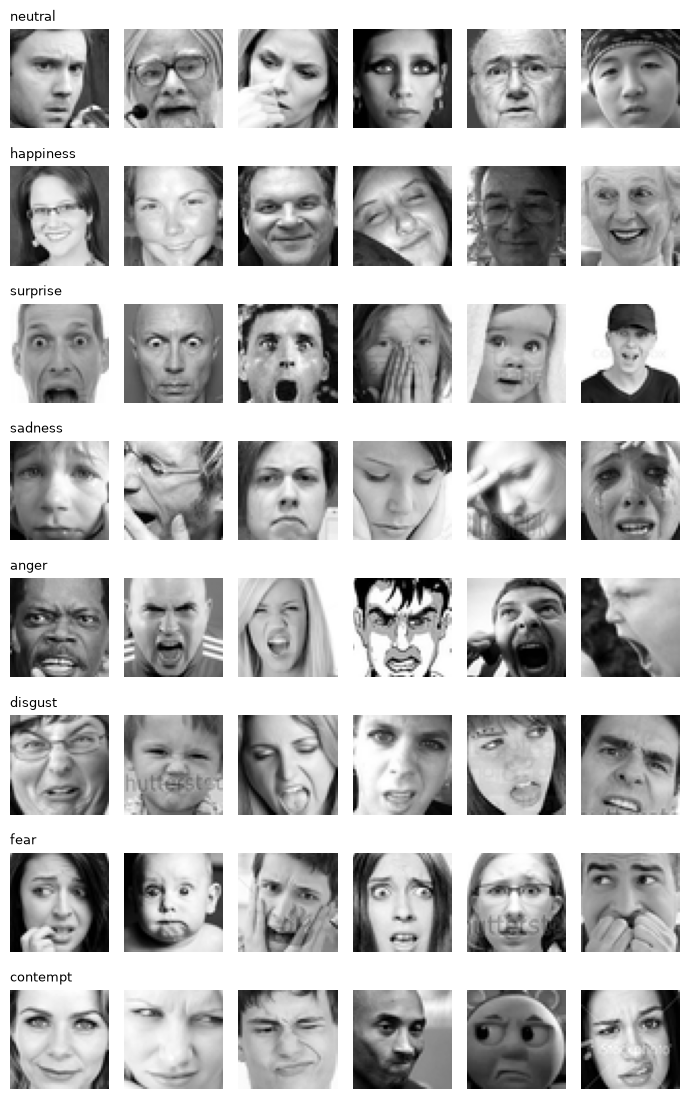

In [ ]:
fig, axes = plt.subplots(len(EMOTIONS), 6, figsize=(7, 1.4 * len(EMOTIONS)))
for r, emotion in enumerate(EMOTIONS):
    examples = [image for image, e in data['train'] if e == emotion][:6]
    for c in range(6):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(examples):
            ax.imshow(examples[c], cmap='gray')
        if c == 0:
            ax.set_title(emotion, loc='left', fontsize=9)
plt.tight_layout()
plt.show()

## 2e. Check for duplicate images

If the same image appears in both the training and test sets, the model is tested on something it has already seen, which inflates accuracy (leakage). We fingerprint every image with a hash: identical images get identical fingerprints. We count duplicates inside the training set, training images that also appear in validation or test, and duplicates that carry different labels.

In [ ]:
import hashlib

def image_hash(image):
    return hashlib.md5(image.tobytes()).hexdigest()

hashes = {}   # split -> {fingerprint: [(image, emotion), ...]}
for split, items in data.items():
    hashes[split] = {}
    for image, emotion in items:
        hashes[split].setdefault(image_hash(image), []).append((image, emotion))

for split in hashes:
    n_images = sum(len(v) for v in hashes[split].values())
    print(f'{split}: {n_images} images, {len(hashes[split])} unique')

for split in ['val', 'test']:
    print(f'identical images in both train and {split}:', len(set(hashes['train']) & set(hashes[split])))

conflicts = sum(1 for v in hashes['train'].values() if len({e for _, e in v}) > 1)
print('train duplicates with conflicting labels:', conflicts)

train: 26940 images, 25784 unique
val: 3396 images, 3371 unique
test: 3376 images, 3360 unique
identical images in both train and val: 255
identical images in both train and test: 266
train duplicates with conflicting labels: 0


## 2f. Remove problem images from training

Using the fingerprints from 2e, we build a clean list of training images. We remove:
- **images also in the validation or test set**, so the model is never checked on an image it trained on
- **extra copies**, keeping one copy of each repeated image
- **repeated images with conflicting labels**, since we can't tell which label is right
- **blank images** (every pixel nearly the same shade), which have no face

The validation and test sets are left exactly as published, so our results stay comparable with other work on FER+.

In [ ]:
# Fingerprints of every validation and test image, for fast "is this also there?" lookups
held_out = set(hashes['val']) | set(hashes['test'])
train_data = []   # (image, emotion) of every training image we keep
removed = {'also in val/test': 0, 'extra copy': 0, 'conflicting labels': 0, 'blank': 0}

# hashes['train'] groups training images by fingerprint:
#   h      = the fingerprint of one unique image
#   copies = every image with that fingerprint, as (image, emotion) pairs
for h, copies in hashes['train'].items():

    # 1. Also in validation or test: drop every copy
    if h in held_out:
        removed['also in val/test'] += len(copies)
        continue   # skip to the next image

    # 2. Conflicting labels: more than one emotion among the copies, so drop them all
    if len({emotion for _, emotion in copies}) > 1:
        removed['conflicting labels'] += len(copies)
        continue

    # 3. Extra copies: keep only the first copy, count the rest as removed
    removed['extra copy'] += len(copies) - 1
    image, emotion = copies[0]

    # 4. Blank image: std() measures how much the pixel brightness varies.
    #    A real face has light and dark areas (std well above 1);
    #    a blank image is nearly one shade (std close to 0)
    if np.array(image).std() < 1:
        removed['blank'] += 1
        continue

    # Passed every check: keep it for training
    train_data.append((image, emotion))

val_data, test_data = data['val'], data['test']
print('Removed:', removed)
print('Training images kept:', len(train_data), 'of', len(data['train']))

# Add the clean training counts per emotion to the table from 2c
kept = pd.Series([emotion for _, emotion in train_data]).value_counts()
table['train (clean)'] = kept
table.loc['TOTAL', 'train (clean)'] = kept.sum()
table = table.fillna(0).astype(int)
display(table)

Removed: {'also in val/test': 660, 'extra copy': 1001, 'conflicting labels': 0, 'blank': 0}
Training images kept: 25279 of 26940


,train,val,test,train (clean)
neutral,9365,1242,1166,9094
happiness,7410,880,909,7183
surprise,3378,441,421,2697
sadness,3403,395,424,3214
anger,2399,310,316,2230
disgust,175,31,22,142
fear,648,73,92,571
contempt,162,24,26,148
TOTAL,26940,3396,3376,25279


## 2g. Dataset summary

| | |
|---|---|
| **Task** | Image classification: given a face image, predict one of 8 emotions |
| **Input** | 48x48 grayscale face images, already cropped and centered |
| **Labels** | neutral, happiness, surprise, sadness, anger, disgust, fear, contempt. One label per image (2b) |
| **Size** | 35,887 images, minus those marked "unknown", "not a face" or unclear (counts printed in 2b) |
| **Splits** | Official FER+ splits kept as published: Training for training, PublicTest for validation, PrivateTest for test. Validation is used to pick the best epoch; test is used once, for final results. The clean training count is printed in 2f |
| **Subsets** | For the limited-data experiments, we train on 10%, 25%, 50% and 100% of the clean training images, keeping each emotion's share the same. Validation and test are never reduced |

**Known characteristics**
- **Class imbalance:** neutral and happiness have thousands of training images, while disgust and contempt have under 200 each. A model can score high overall accuracy while missing rare emotions, so we also look at accuracy per emotion in the confusion matrices.
- **Limited data for rare emotions:** at the 10% subset, disgust and contempt have under 20 training images each, so low accuracy on them is expected.
- **Label quality:** emotions are subjective and people often disagree. FER+ labels are more reliable than single-person labels, but some ambiguous faces remain.
- **Duplicates and leakage:** some identical images appear more than once, including some shared between training and validation/test (2e). These are removed from training in 2f.
- **Image quality:** images come from web searches, so some include stock-photo watermarks, hands covering the face, or turned heads.

**Citations**
- FER+ labels: E. Barsoum, C. Zhang, C. Canton Ferrer and Z. Zhang. *Training Deep Networks for Facial Expression Recognition with Crowd-Sourced Label Distribution.* ACM International Conference on Multimodal Interaction (ICMI), 2016. [github.com/microsoft/FERPlus](https://github.com/microsoft/FERPlus)
- FER-2013 images: I. J. Goodfellow et al. *Challenges in Representation Learning: A Report on Three Machine Learning Contests.* International Conference on Neural Information Processing (ICONIP), 2013.

```bibtex
@inproceedings{BarsoumICMI2016,
    title={Training Deep Networks for Facial Expression Recognition with Crowd-Sourced Label Distribution},
    author={Barsoum, Emad and Zhang, Cha and Canton Ferrer, Cristian and Zhang, Zhengyou},
    booktitle={ACM International Conference on Multimodal Interaction (ICMI)},
    year={2016}
}
```

# 3. Prepare the Data for Training

Turns the clean image lists from Section 2 into something PyTorch can train on: a transform that turns images into numbers, a dataset class, the 10/25/50/100% training subsets, and data loaders that feed images to the model in batches. Augmentation is not added yet; we first train without it to get a baseline. FER+ already has an official validation split (PublicTest), so we use it as published instead of setting training images aside.

## 3a. Image transform

A model works with numbers, not images. The transform runs on every image as it is loaded:
- `Grayscale(1)`: makes sure every image has a single channel (the faces are black and white)
- `ToTensor()`: turns the 48x48 pixels into a PyTorch tensor with values from 0 to 1
- `Normalize((0.5,), (0.5,))`: shifts the values to range from -1 to 1, centered on 0, which helps training run smoothly

This is the plain transform used for the "augmentation off" runs. The augmented version is added later.

In [ ]:
plain_transform = transforms.Compose([
    transforms.Grayscale(1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

## 3b. Dataset class

PyTorch reads data through a `Dataset`: an object that says how many images there are (`__len__`) and how to get image number *i* (`__getitem__`). Ours takes a list of `(image, emotion)` pairs, applies the transform, and returns the image tensor with its emotion as a number (0 to 7, in the order of `emotions`). All images are already in memory from Section 2, so loading is fast.

In [ ]:
class FaceDataset(torch.utils.data.Dataset):
    def __init__(self, items, transform):
        self.items = items            # list of (image, emotion) pairs
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        image, emotion = self.items[i]
        return self.transform(image), emotions.index(emotion)   # (tensor, label number)

print('Label numbers:', dict(enumerate(emotions)))

Label numbers: {0: 'neutral', 1: 'happiness', 2: 'surprise', 3: 'sadness', 4: 'anger', 5: 'disgust', 6: 'fear', 7: 'contempt'}


## 3c. Training subsets

To test how each model handles limited data, we train on 10%, 25%, 50% and 100% of the clean training images. Each subset is **stratified**: we take the same fraction of *each emotion* separately, so every subset keeps the same mix of emotions. Without this, a rare emotion like contempt could end up with almost no images in a small subset. Validation and test sets stay the same for every run, so results are directly comparable.

In [ ]:
def stratified_sample(items, fraction, seed=SEED):
    """Take `fraction` of the images from each emotion. Returns (picked, rest)."""
    rng = random.Random(seed)   # fixed seed, so the same images are picked every run
    picked, rest = [], []
    for emotion in emotions:
        group = [item for item in items if item[1] == emotion]   # all images of this emotion
        rng.shuffle(group)
        n = round(len(group) * fraction)
        picked += group[:n]
        rest += group[n:]
    return picked, rest

FRACTIONS = [0.10, 0.25, 0.50, 1.00]
subsets = {f: stratified_sample(train_data, f)[0] for f in FRACTIONS}

subset_table = pd.DataFrame({f'{int(f * 100)}%': pd.Series([e for _, e in items]).value_counts()
                             for f, items in subsets.items()}).reindex(emotions).fillna(0).astype(int)
subset_table.loc['TOTAL'] = subset_table.sum()
display(subset_table)
print('validation:', len(val_data), '| test:', len(test_data))

,10%,25%,50%,100%
neutral,909,2274,4547,9094
happiness,718,1796,3592,7183
surprise,270,674,1348,2697
sadness,321,804,1607,3214
anger,223,558,1115,2230
disgust,14,36,71,142
fear,57,143,286,571
contempt,15,37,74,148
TOTAL,2527,6322,12640,25279


validation: 3396 | test: 3376


## 3d. Data loaders

A `DataLoader` feeds the dataset to the model in **batches** of 64 images at a time, instead of one by one, which is much faster on a GPU. Training batches are shuffled each epoch so the model doesn't see images in the same order every time; validation and test are not shuffled since order doesn't matter there. Two background workers prepare images while the GPU trains; on Windows this often freezes inside a notebook, so there we prepare images in the main process instead (`num_workers=0`). We load one batch to check the shapes: 64 images, 1 channel, 48x48 pixels.

In [ ]:
BATCH_SIZE = 64
NUM_WORKERS = 0 if os.name == 'nt' else 2   # 'nt' = Windows

def make_loader(items, transform, shuffle):
    return DataLoader(FaceDataset(items, transform), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=NUM_WORKERS,
                      persistent_workers=NUM_WORKERS > 0)   # keep workers between epochs

val_loader = make_loader(val_data, plain_transform, shuffle=False)
test_loader = make_loader(test_data, plain_transform, shuffle=False)

images, labels = next(iter(make_loader(subsets[1.00], plain_transform, shuffle=True)))
print('Batch of images:', tuple(images.shape), '| batch of labels:', tuple(labels.shape))

Batch of images: (64, 1, 48, 48) | batch of labels: (64,)


# 4. Model 1: Plain CNN from Scratch

Our baseline model is a plain convolutional neural network (CNN) that we built ourselves. It has three convolution blocks that learn patterns in the face, from simple edges to larger features like a smile, followed by a small classifier that turns those patterns into one score per emotion.

**A note on naming:** both of our models are CNNs, since a ResNet is also a convolutional network. The difference is that this model is a *plain* stack of layers, while the ResNet (Section 5) adds skip connections. Its design is **VGG-style** (Simonyan and Zisserman, 2014): repeated pairs of 3x3 convolutions followed by max pooling, with the number of filters doubling each block. It is much smaller than the original VGG-16 (about 1.5 million parameters instead of 138 million) and adds batch normalization and dropout. In this project, "CNN" means this plain VGG-style model.

## 4a. Convolution block

Each block repeats the same steps twice: a 3x3 convolution that learns patterns, batch normalization that keeps values in a steady range, and ReLU, which keeps positive values and sets negatives to 0. The block ends with max pooling, which halves the image's width and height. Writing it once as a function keeps the model short.

In [ ]:
def conv_block(in_channels, out_channels):
    """Two 3x3 convolutions, then halve the image size."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

## 4b. The CNN

Three blocks with 32, 64 and 128 filters shrink the 48x48 image to 6x6 while learning more and more detailed features. The classifier then flattens the result into one row of 4,608 numbers, mixes them into 256 features, and outputs one score per emotion. Dropout switches off half of the 256 features at random during training, so the model can't depend on any single one (this reduces overfitting).

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=len(emotions)):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 32),     # 1 x 48 x 48  -> 32 x 24 x 24
            conv_block(32, 64),    # 32 x 24 x 24 -> 64 x 12 x 12
            conv_block(64, 128),   # 64 x 12 x 12 -> 128 x 6 x 6
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # 128 x 6 x 6 -> 4,608
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),   # one score per emotion
        )

    def forward(self, x):
        return self.classifier(self.features(x))

## 4c. Check the model

The course asks us to report each model's size, so we count its parameters (the numbers it learns during training). We also pass the batch from 3d through the untrained model to confirm the shapes line up: 64 images in, 64 rows of 8 emotion scores out.

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

cnn = SimpleCNN().to(device)
print(cnn)
print(f'Parameters: {count_params(cnn):,}')

scores = cnn(images.to(device))
print('Output shape:', tuple(scores.shape))

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)


# 5. Model 2: ResNet from Scratch

Our second model is a small **ResNet** (residual network, He et al., 2016), also built from scratch. It is still a CNN, but it adds one idea: **skip connections**. Each residual block adds its input back onto its output, so the block only has to learn a *change* to what it was given. This makes deeper networks easier to train, because the signal and its gradients can flow straight through the skip path.

Comparing it with the plain CNN from Section 4 tests whether skip connections help when training data is limited, with and without augmentation.

## 5a. Residual block

A residual block has two 3x3 convolutions with batch normalization, like the plain CNN. The difference is the last step: the block's input is added to the result before the final ReLU. When a block halves the image size (`stride=2`) or changes the number of filters, the input no longer matches the output shape, so a 1x1 convolution on the skip path reshapes it first.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Skip path: pass the input straight through, or reshape it with a 1x1 convolution
        # when this block changes the image size or the number of filters
        if stride != 1 or in_channels != out_channels:
            self.skip = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.skip(x))   # add the input back: the skip connection

## 5b. The ResNet

A first convolution turns the grayscale image into 32 feature maps. Then come three stages of two residual blocks each, with 32, 64 and 128 filters; the second and third stages halve the image size, so 48x48 becomes 24x24 and then 12x12. Instead of flattening, **global average pooling** averages each of the 128 feature maps into a single number, and one linear layer turns those 128 numbers into one score per emotion. This is the standard ResNet layout, scaled down for small 48x48 images.

In [ ]:
class SmallResNet(nn.Module):
    def __init__(self, num_classes=len(emotions)):
        super().__init__()
        self.stem = nn.Sequential(                       # 1 x 48 x 48 -> 32 x 48 x 48
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
        )
        self.stages = nn.Sequential(
            ResidualBlock(32, 32), ResidualBlock(32, 32),               # 32 x 48 x 48
            ResidualBlock(32, 64, stride=2), ResidualBlock(64, 64),     # 64 x 24 x 24
            ResidualBlock(64, 128, stride=2), ResidualBlock(128, 128),  # 128 x 12 x 12
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),        # average each feature map -> 128 x 1 x 1
            nn.Flatten(),                   # -> 128
            nn.Linear(128, num_classes),    # one score per emotion
        )

    def forward(self, x):
        return self.classifier(self.stages(self.stem(x)))

## 5c. Check the model

As in 4c, we count the parameters and pass the batch from 3d through the untrained model. The ResNet has about half as many parameters as the plain CNN, because global average pooling replaces the CNN's large 4,608 x 256 linear layer. We report both counts so the comparison is transparent.

In [ ]:
resnet = SmallResNet().to(device)
print(resnet)
print(f'Parameters: {count_params(resnet):,}  (plain CNN: {count_params(cnn):,})')

scores = resnet(images.to(device))
print('Output shape:', tuple(scores.shape))

SmallResNet(
  (stem): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (stages): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (skip): Identity()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): Bat

# 6. Training

This section trains every combination in our experiment and saves each result to Google Drive:

| Factor | Settings |
|---|---|
| Model | plain CNN, ResNet |
| Training data | 10%, 25%, 50%, 100% |
| Augmentation | off, on |
| Optimizer | SGD with momentum, AdamW |

That is 2 x 4 x 2 x 2 = **32 training runs**. Every run uses the same seed, the same validation set and the same test set, so differences come from the factors above.

## 6a. Augmented transform

Augmentation makes small random changes to each training image every time it is loaded, so the model sees a slightly different version each epoch. This acts like extra training data and reduces overfitting. We only use changes that keep the expression the same:
- `RandomHorizontalFlip()`: mirrors the face half of the time (a mirrored smile is still a smile)
- `RandomRotation(10)`: tilts the face by up to 10 degrees
- `RandomResizedCrop(48, scale=(0.85, 1.0))`: zooms in slightly on a random part of the face, then resizes back to 48x48

The rest matches the plain transform from 3a. Augmentation is only used for training images; validation and test always use the plain transform.

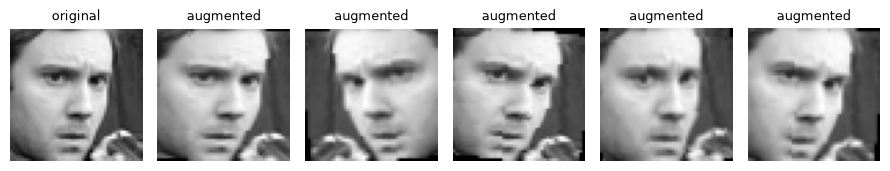

In [ ]:
aug_transform = transforms.Compose([
    transforms.Grayscale(1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(48, scale=(0.85, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

# Show one training face with 5 random augmentations of it
image, emotion = train_data[0]
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
axes[0].imshow(plain_transform(image)[0], cmap='gray')
axes[0].set_title('original', fontsize=9)
for ax in axes[1:]:
    ax.imshow(aug_transform(image)[0], cmap='gray')
    ax.set_title('augmented', fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6b. One pass over the data

`run_epoch` goes through a data loader once. With an optimizer it **trains**: for each batch it computes the scores, measures the error with **cross-entropy loss** (the standard loss for classification), works out how each weight should change (`loss.backward()`), and updates the weights (`optimizer.step()`). Without an optimizer it only **evaluates**, with gradients turned off. Either way it returns the average loss and the accuracy.

`model.train()` and `model.eval()` matter because dropout and batch normalization behave differently while training: dropout is switched off and batch normalization uses its saved averages during evaluation.

In [ ]:
loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains if an optimizer is given, otherwise just evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            scores = model(images)
            loss = loss_fn(scores, labels)
            if training:
                optimizer.zero_grad()   # clear the previous batch's gradients
                loss.backward()         # work out how each weight should change
                optimizer.step()        # update the weights
            total_loss += loss.item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

def predict(model, loader):
    """Returns the true labels and the model's predicted labels for every image in the loader."""
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            pred += model(images.to(device)).argmax(dim=1).cpu().tolist()
            true += labels.tolist()
    return true, pred

## 6c. One training run

`train_model` trains one model with one combination of settings:
- **Optimizer:** SGD with momentum (learning rate 0.01) or AdamW (learning rate 0.001). Both use weight decay, a small penalty on large weights that reduces overfitting.
- **Learning rate schedule:** cosine annealing lowers the learning rate smoothly to near 0 over the run, so training takes big steps early and fine-tunes at the end.
- **Epochs:** every run trains for the same number of epochs (`EPOCHS`).
- **Progress:** each epoch prints the training accuracy and loss and the validation accuracy and loss, so you can watch the model learn.
- **Model selection:** after each epoch we check validation accuracy and keep a copy of the weights from the **best validation epoch**. The test set plays no part in this choice.

The seed is reset at the start of every run, so each run starts from the same random weights and sees images in the same order.

In [ ]:
import copy, json
from sklearn.metrics import precision_recall_fscore_support

EPOCHS = 30
MODELS = {'CNN': SimpleCNN, 'ResNet': SmallResNet}

def make_optimizer(name, model):
    if name == 'SGD':
        return torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
    return torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

def train_model(model_name, fraction, augment, opt_name):
    set_seed(SEED)
    model = MODELS[model_name]().to(device)
    optimizer = make_optimizer(opt_name, model)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_loader(subsets[fraction], aug_transform if augment else plain_transform, shuffle=True)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc, best_weights = -1, None
    for epoch in range(EPOCHS):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        scheduler.step()
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        if val_acc > best_val_acc:   # keep the weights from the best validation epoch
            best_val_acc, best_weights = val_acc, copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch + 1}/{EPOCHS} - accuracy: {train_acc:.4f} - loss: {train_loss:.4f} '
              f'- val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f}')

    model.load_state_dict(best_weights)
    return model, history

## 6d. Run every combination

This loop trains all 32 runs. After training, each run prints its scores on the **test set** (images the model never trained on, using the weights from its best validation epoch): accuracy, plus macro precision, recall and F1, where every emotion counts equally. After each run it predicts every test image with the best-validation weights and saves a small results file in the `results_ferplus/` folder inside `PROJECT_DIR` (Google Drive in Colab, `project_data` on your own computer): the settings, the learning curves, the best validation accuracy, and the test predictions.

**Colab can disconnect during long jobs.** Runs that already have a results file are skipped, so if the session stops, just reconnect, run the notebook from the top again, and the loop continues where it left off. Expect roughly a few hours in total on a T4 GPU; each run prints its time when it finishes.

In [ ]:
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results_ferplus')
os.makedirs(RESULTS_DIR, exist_ok=True)

for model_name in MODELS:
    for opt_name in ['SGD', 'AdamW']:
        for augment in [False, True]:
            for fraction in FRACTIONS:
                run_name = f"{model_name}_{opt_name}_{'aug' if augment else 'noaug'}_{int(fraction * 100)}"
                result_path = os.path.join(RESULTS_DIR, run_name + '.json')
                if os.path.exists(result_path):
                    print('already done:', run_name)
                    continue

                print(f'\n=== {run_name} ===')
                start = time.time()
                model, history = train_model(model_name, fraction, augment, opt_name)
                true, pred = predict(model, test_loader)
                test_acc = np.mean(np.array(true) == np.array(pred))

                result = {'model': model_name, 'optimizer': opt_name, 'augment': augment,
                          'fraction': fraction, 'train_images': len(subsets[fraction]),
                          'parameters': count_params(model), 'best_val_acc': max(history['val_acc']),
                          'test_acc': test_acc, 'history': history,
                          'test_true': true, 'test_pred': pred}
                with open(result_path, 'w') as f:
                    json.dump(result, f)
                precision, recall, f1, _ = precision_recall_fscore_support(true, pred, average='macro', zero_division=0)
                print(f'Test Accuracy: {test_acc:.4f}')
                print(f'Macro Precision: {precision:.4f}')
                print(f'Macro Recall:    {recall:.4f}')
                print(f'Macro F1-score:  {f1:.4f}')
                print(f'({(time.time() - start) / 60:.1f} min)')


=== CNN_SGD_noaug_10 ===
Epoch 1/30 - accuracy: 0.3411 - loss: 1.6823 - val_accuracy: 0.3866 - val_loss: 1.6412
Epoch 2/30 - accuracy: 0.3882 - loss: 1.5481 - val_accuracy: 0.4208 - val_loss: 1.4971
Epoch 3/30 - accuracy: 0.4464 - loss: 1.4732 - val_accuracy: 0.5318 - val_loss: 1.3501
Epoch 4/30 - accuracy: 0.4990 - loss: 1.3816 - val_accuracy: 0.5088 - val_loss: 1.4441
Epoch 5/30 - accuracy: 0.5433 - loss: 1.3191 - val_accuracy: 0.5398 - val_loss: 1.3087
Epoch 6/30 - accuracy: 0.5429 - loss: 1.2953 - val_accuracy: 0.5698 - val_loss: 1.2500
Epoch 7/30 - accuracy: 0.5916 - loss: 1.2026 - val_accuracy: 0.5819 - val_loss: 1.2514
Epoch 8/30 - accuracy: 0.5940 - loss: 1.1785 - val_accuracy: 0.5733 - val_loss: 1.2475
Epoch 9/30 - accuracy: 0.6173 - loss: 1.1277 - val_accuracy: 0.6231 - val_loss: 1.1290
Epoch 10/30 - accuracy: 0.6450 - loss: 1.0544 - val_accuracy: 0.6163 - val_loss: 1.1722
Epoch 11/30 - accuracy: 0.6533 - loss: 0.9958 - val_accuracy: 0.6272 - val_loss: 1.1178
Epoch 12/30 - a

# 7. Results

All results are read back from the files saved in Section 6 (to Google Drive in Colab, or the `project_data` folder on your own computer), so after training is finished this section can be run in a fresh session. Run every cell from the top **except 6d** (the only slow one); the other cells just rebuild the data, models and settings this section uses.

The section shows four things: the **test accuracy** of every run and how much augmentation added (7a, 7b), the **loss and accuracy curves** during training (7c), the **confusion matrices** (7d), and examples of mistakes (7e). Curves and confusion matrices are shown for the CNN and the ResNet, each **with and without augmentation**, so the effect of augmentation can be seen side by side.

## 7a. Test accuracy and augmentation gain

The first table is the test accuracy (%) of every run: one row per model, optimizer and augmentation setting, one column per training data size.

The second table answers the research question directly: the accuracy **with augmentation minus without it**, in percentage points, for the same model, optimizer and data size. A positive number means augmentation helped. Comparing the CNN and ResNet rows shows whether it helped one architecture more, and reading across shows whether the gain changes as more data is used.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RESULTS_DIR = os.path.join(PROJECT_DIR, 'results_ferplus')
runs = []
for name in sorted(os.listdir(RESULTS_DIR)):
    with open(os.path.join(RESULTS_DIR, name)) as f:
        runs.append(json.load(f))
print(len(runs), 'runs loaded')

results = pd.DataFrame([{
    'model': r['model'], 'optimizer': r['optimizer'],
    'augmentation': 'on' if r['augment'] else 'off',
    'data %': int(r['fraction'] * 100), 'test acc': r['test_acc'] * 100,
} for r in runs])

acc = results.pivot_table(index=['model', 'optimizer', 'augmentation'], columns='data %', values='test acc')
print('Test accuracy (%):')
display(acc.round(1))

gain = acc.xs('on', level='augmentation') - acc.xs('off', level='augmentation')
print('Augmentation gain (percentage points):')
display(gain.round(1))

32 runs loaded
Test accuracy (%):


data %                          10    25    50    100
model  optimizer augmentation                        
CNN    AdamW     off           64.0  70.4  74.8  77.6
                 on            67.2  73.0  76.6  80.3
       SGD       off           63.5  70.3  75.0  77.7
                 on            64.9  71.9  77.1  80.7
ResNet AdamW     off           63.8  71.9  75.6  78.6
                 on            70.6  77.0  79.5  81.8
       SGD       off           57.0  68.1  74.0  77.5
                 on            67.6  76.5  79.4  83.1

Augmentation gain (percentage points):


data %             10   25   50   100
model  optimizer                     
CNN    AdamW       3.2  2.7  1.8  2.8
       SGD         1.4  1.6  2.0  3.0
ResNet AdamW       6.8  5.1  3.9  3.2
       SGD        10.6  8.4  5.5  5.6

## 7b. Accuracy vs training data size

The same test accuracies as a chart. Each line is one model with augmentation off (dashed) or on (solid); one panel per optimizer. The gap between a dashed line and the solid line of the same color is how much augmentation helped that model.

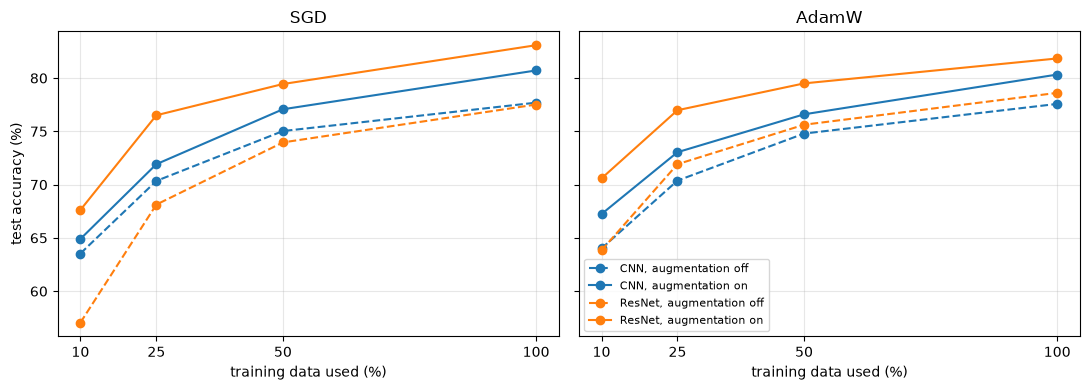

In [ ]:
colors = {'CNN': 'tab:blue', 'ResNet': 'tab:orange'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, opt_name in zip(axes, ['SGD', 'AdamW']):
    for model_name in MODELS:
        for aug, style in [('off', '--'), ('on', '-')]:
            rows = results[(results['model'] == model_name) & (results['optimizer'] == opt_name)
                           & (results['augmentation'] == aug)].sort_values('data %')
            ax.plot(rows['data %'], rows['test acc'], style, marker='o', color=colors[model_name],
                    label=f'{model_name}, augmentation {aug}')
    ax.set_title(opt_name)
    ax.set_xlabel('training data used (%)')
    ax.set_xticks([int(f * 100) for f in FRACTIONS])
    ax.grid(alpha=0.3)
axes[0].set_ylabel('test accuracy (%)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7c. Loss and accuracy curves

Four runs side by side, all on 100% of the training data: the CNN and the ResNet, each with augmentation off and on. For each of the four, we show the run (SGD or AdamW) with the best validation accuracy; the optimizer is named in the title. The top row is the **loss** and the bottom row the **accuracy** over the epochs, for the training images and the validation images. The dashed line is the final **test accuracy**. The test set is only scored once at the end, so validation is what we track during training.

How to read it:
- Both losses going down means the model is learning.
- **Overfitting:** training loss keeps falling while validation loss flattens or rises, and training accuracy climbs far above validation accuracy. The model is memorizing its training images instead of learning patterns that work on new faces.
- **Augmentation off vs on:** compare the gap between the training and validation lines. A smaller gap means augmentation reduced overfitting. With augmentation on, training accuracy can even sit below validation accuracy, because the training images are randomly flipped, rotated and cropped, which makes them harder than the plain validation images.

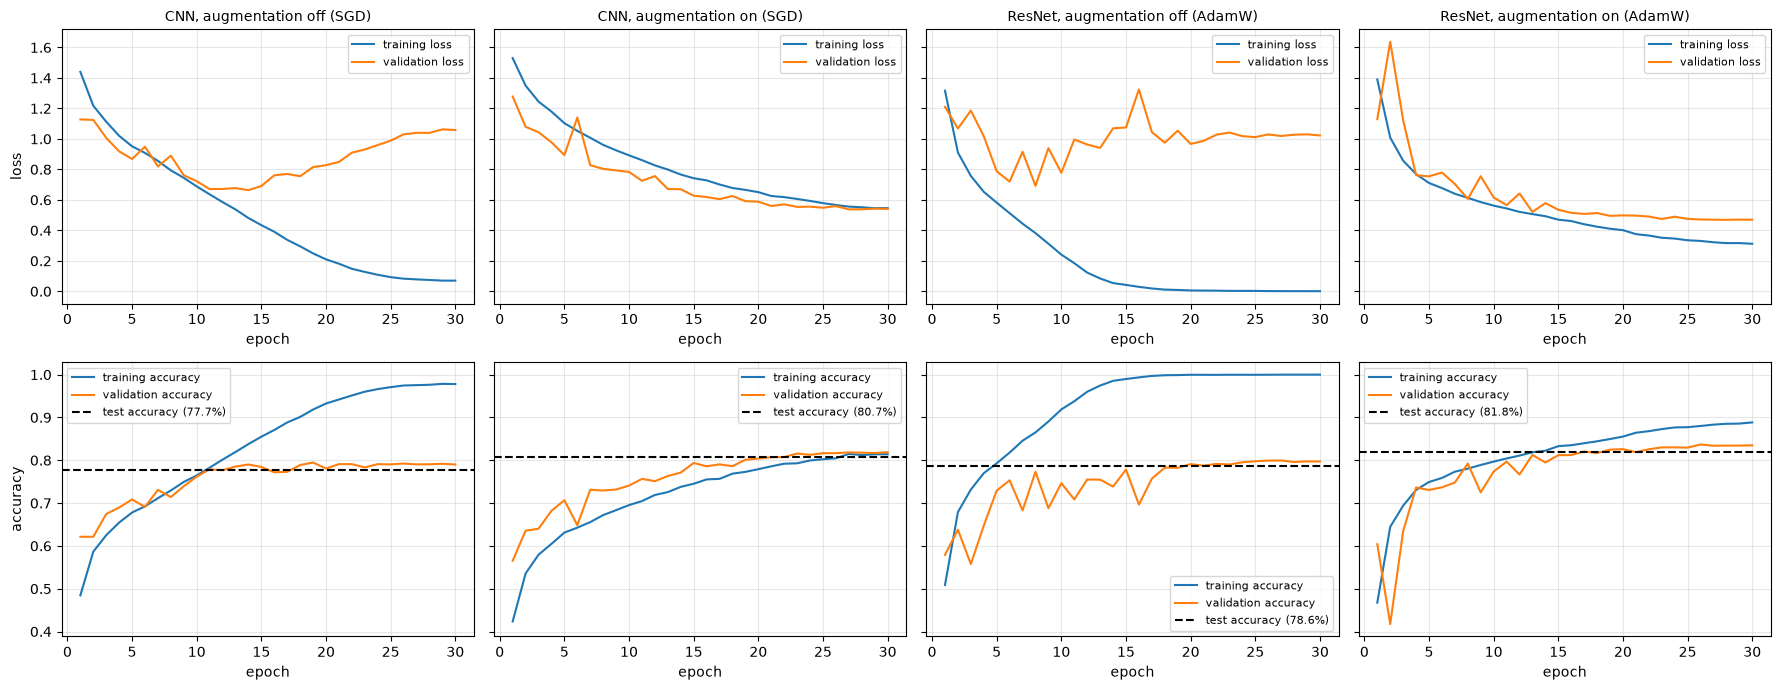

In [ ]:
def best_run(model_name, augment):
    """The run on 100% of the data with the best validation accuracy, for one model and augmentation setting."""
    candidates = [r for r in runs if r['model'] == model_name and r['augment'] == augment and r['fraction'] == 1.0]
    return max(candidates, key=lambda r: r['best_val_acc'])

panels = [(model_name, augment) for model_name in MODELS for augment in [False, True]]
best = {panel: best_run(*panel) for panel in panels}

def panel_title(model_name, augment):
    r = best[(model_name, augment)]
    return f"{model_name}, augmentation {'on' if augment else 'off'} ({r['optimizer']})"

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey='row')
for col, (model_name, augment) in enumerate(panels):
    r = best[(model_name, augment)]
    h = r['history']
    epochs = range(1, len(h['train_loss']) + 1)

    ax = axes[0, col]   # top row: loss
    ax.plot(epochs, h['train_loss'], label='training loss')
    ax.plot(epochs, h['val_loss'], label='validation loss')
    ax.set_title(panel_title(model_name, augment), fontsize=10)
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    ax = axes[1, col]   # bottom row: accuracy
    ax.plot(epochs, h['train_acc'], label='training accuracy')
    ax.plot(epochs, h['val_acc'], label='validation accuracy')
    ax.axhline(r['test_acc'], color='black', linestyle='--', label=f"test accuracy ({r['test_acc']:.1%})")
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel('loss')
axes[1, 0].set_ylabel('accuracy')
plt.tight_layout()
plt.show()

## 7d. Confusion matrices

The same four runs as 7c. Each row is the true emotion and each column is the model's guess, so the diagonal holds the correct answers. Rows are normalized to sum to 1, so each cell is the share of that emotion's test images given that guess, and the diagonal is the accuracy for each emotion. Darker cells off the diagonal show which emotions the models mix up, for example sadness with neutral, or fear with surprise.

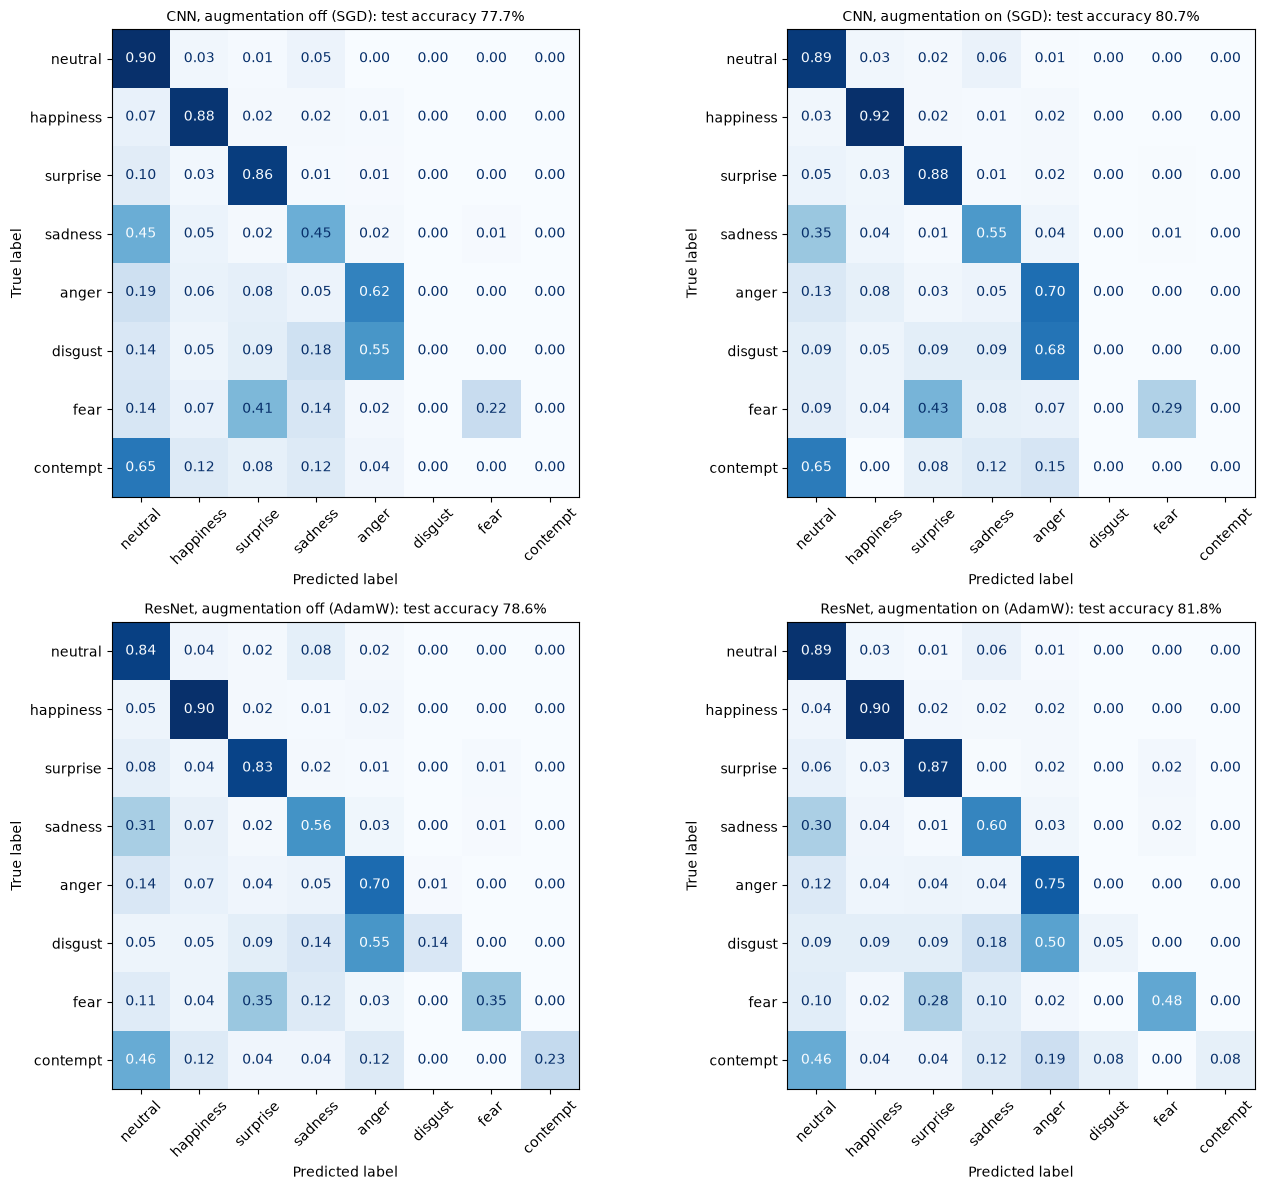

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (model_name, augment) in zip(axes.flat, panels):
    r = best[(model_name, augment)]
    cm = confusion_matrix(r['test_true'], r['test_pred'], labels=range(len(emotions)), normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=emotions).plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    ax.set_title(f"{panel_title(model_name, augment)}: test accuracy {r['test_acc']:.1%}", fontsize=10)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 7e. Error analysis

Examples of test images that the best ResNet (augmentation on) got wrong, with the true label and the model's guess. Looking at them shows *why* the model fails: some faces are ambiguous even to people, some labels look wrong, and some images are hard (turned heads, hands over the face, watermarks).

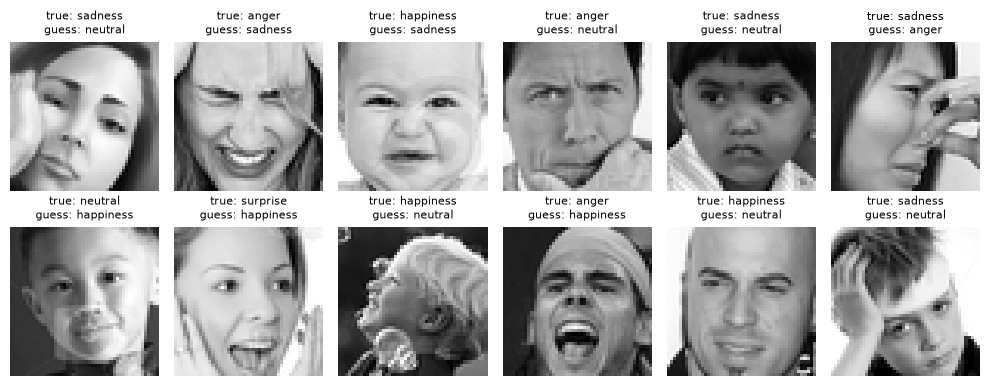

In [ ]:
r = best[('ResNet', True)]
wrong = [i for i, (t, p) in enumerate(zip(r['test_true'], r['test_pred'])) if t != p]
random.Random(SEED).shuffle(wrong)

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, i in zip(axes.flat, wrong[:12]):
    ax.imshow(test_data[i][0], cmap='gray')
    ax.set_title(f"true: {emotions[r['test_true'][i]]}\nguess: {emotions[r['test_pred'][i]]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

# 8. Conclusion

*Fill in after the results are in.*

**Answer to the research question:**
- How much did augmentation improve the plain CNN and the ResNet at each data size (7a, 7b)?
- Did it help one architecture more than the other?
- Did the gain shrink as more training data was used?

**Other findings:**
- SGD vs AdamW (the optimizer rows in 7a)
- Overfitting, and whether augmentation reduced it (7c)
- Which emotions were hardest, and which were confused with each other (7d, 7e)

**Limitations:**
- FER+'s labels are subjective, and some are likely wrong, which caps the accuracy any model can reach.
- The emotions are very imbalanced, so rare emotions are learned poorly, especially on small subsets.
- Every combination was run once with one seed; repeating runs with several seeds would show how much results vary by chance.
- All runs use the same number of epochs, so small subsets get fewer weight updates in total.
- Faces are already cropped and centered; a real application would also need a face detector.

**Ethics:** emotion recognition can be biased across age, gender and ethnicity, and reading someone's emotions without consent raises privacy concerns. It should not be used for high-stakes decisions about people.

## 8a. Reproducibility

The software versions and hardware used for the results above.

In [ ]:
import sys, platform, torchvision

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU)')
print('Platform:', platform.platform())
print('Seed:', SEED, '| epochs:', EPOCHS, '| batch size:', BATCH_SIZE)

Python: 3.12.10
PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
GPU: NVIDIA GeForce RTX 5070 Ti
Platform: Windows-11-10.0.26200-SP0
Seed: 42 | epochs: 30 | batch size: 64
